In [1]:
import numpy as np
from openfermion import FermionOperator, QubitOperator, jordan_wigner, get_fermion_operator

In [3]:
# H2 molecule
from pyscf import gto, scf

# Build molecule
mol = gto.M(
    atom=[["H", (0.0, 0.0, 0.0)],
          ["H", (0.0, 0.0, 0.74)]],
    basis="sto-3g",
    unit="Angstrom",
)

# Hartree-Fock calculation
mf = scf.RHF(mol)
mf.kernel()

converged SCF energy = -1.11675930739643


np.float64(-1.1167593073964255)

In [4]:
from pyscf import fci

# singlets only
cisolver = fci.FCI(mol, mf.mo_coeff)
fci_energy, ci = cisolver.kernel()
print("FCI energy:", fci_energy)

FCI energy: -1.137283834488502


In [5]:
tol_ampl = 0.01

from pyscf.fci import cistring
mc = cisolver

ncas = mc.norb
nelec = mc.nelec

# determinants α i β (representats com enters amb bits d’ocupació)
na, nb = nelec
alpha_det = cistring.make_strings(range(ncas), na)
beta_det = cistring.make_strings(range(ncas), nb)


def interleave_bits(a, b, ncas):
    """Return interleaved occupation string (αβ αβ ...)"""
    a_bits = [(a >> i) & 1 for i in range(ncas)]
    b_bits = [(b >> i) & 1 for i in range(ncas)]
    inter = []
    for i in reversed(range(ncas)):
        inter.append(str(a_bits[i]))
        inter.append(str(b_bits[i]))
    return ''.join(inter)[::-1]

print('\namplitudes FCI')
for i, a in enumerate(alpha_det):
    for j, b in enumerate(beta_det):
        amp = mc.ci[i, j]
        if amp**2 > tol_ampl:
            # print(f"α={format(a, f'0{ncas}b')}  β={format(b, f'0{ncas}b')}  coef={amp:+.6f}")
            cfg = interleave_bits(a, b, ncas)
            print(f"{cfg}   {amp:+.6f}  ({amp**2:.6f}) ")


amplitudes FCI
1100   +0.993647  (0.987334) 
0011   -0.112544  (0.012666) 


In [6]:
from pyscf import ao2mo

C = mf.mo_coeff

# One-electron integrals in MO basis
h1 = mf.get_hcore() # Core Hamiltonian (kinetic + nuclear attraction)
h1_mo = C.T @ h1 @ C

# Two-electron integrals in MO basis (Electron Repulsion Integrals)
eri_mo = ao2mo.kernel(mol, C)
eri_mo = ao2mo.restore(1, eri_mo, C.shape[1])
# h[p,q,r,s] = (ps|qr)
eri_mo = eri_mo.transpose(0, 2, 3, 1)

e_nuc = mf.energy_nuc()

# 1 electron integrals
print(h1_mo)
# 2 electron integrals
print(eri_mo)
print(e_nuc)

[[-1.25330979e+00  3.71049551e-17]
 [ 1.34841040e-17 -4.75068849e-01]]
[[[[ 6.74755927e-01 -3.75785642e-17]
   [-5.45047948e-17  1.81210462e-01]]

  [[-5.45047948e-17  1.81210462e-01]
   [ 6.63711401e-01  4.06319362e-16]]]


 [[[-3.75785642e-17  6.63711401e-01]
   [ 1.81210462e-01  5.57982113e-16]]

  [[ 1.81210462e-01  5.57982113e-16]
   [ 4.06319362e-16  6.97651504e-01]]]]
0.7151043390810812


In [7]:
from openfermion import InteractionOperator, jordan_wigner, get_fermion_operator
from openfermion.chem.molecular_data import spinorb_from_spatial

h1_so, eri_so = spinorb_from_spatial(h1_mo, eri_mo)
hamiltonian = InteractionOperator(e_nuc, h1_so, 0.5 * eri_so)
hamiltonian = get_fermion_operator(hamiltonian)

In [8]:
from openfermion import get_sparse_operator
import numpy as np

H_sparse = get_sparse_operator(hamiltonian)
np.sort(np.linalg.eigvals(H_sparse.toarray()).real)

array([-1.13728383, -0.53820545, -0.53820545, -0.53077336, -0.53077336,
       -0.53077336, -0.44561582, -0.44561582, -0.16835243,  0.24003549,
        0.24003549,  0.3555207 ,  0.3555207 ,  0.48314267,  0.71510434,
        0.92317918])

In [9]:
from openfermion import FermionOperator

D0 = FermionOperator('0^ 1^')
D3 = FermionOperator('2^ 3^')

In [10]:
from openfermion import hermitian_conjugated, normal_ordered

H_matrix = np.zeros((2, 2))
basis = [D0, D3]
print(basis)
for i, b1 in enumerate(basis):
    for j, b2 in enumerate(basis):
        term = normal_ordered(hermitian_conjugated(b1) * hamiltonian * b2)
        H_matrix[i, j] = term.terms.get((), 0.0)
H_matrix

[1.0 [0^ 1^], 1.0 [2^ 3^]]


array([[-1.11675931,  0.18121046],
       [ 0.18121046,  0.46261815]])

In [11]:
import numpy as np

np.linalg.eigvals(H_matrix)


array([-1.13728383,  0.48314267])

In [12]:
from openfermion import QubitOperator

I = QubitOperator(())

# qubit 0
P00 = 0.5 * (I + QubitOperator("Z0"))
P01 = 0.5 * (QubitOperator("X0") + 1j * QubitOperator("Y0"))
P10 = 0.5 * (QubitOperator("X0") - 1j * QubitOperator("Y0"))
P11 = 0.5 * (I - QubitOperator("Z0"))

ha_qubit = (P00 * H_matrix[0, 0] +
            P01 * H_matrix[0, 1] +
            P10 * H_matrix[1, 0] +
            P11 * H_matrix[1, 1])

print(ha_qubit)

-0.3270705806846195 [] +
0.18121046201519675 [X0] +
-0.7896887267118053 [Z0]


In [13]:
np.linalg.eigvals(get_sparse_operator(ha_qubit).toarray())

array([-1.13728383+0.j,  0.48314267+0.j])

In [14]:
# a b a b a b
state = FermionOperator('') # |0>
# state = FermionOperator('0^') # |1>
# state = 1/np.sqrt(2) * FermionOperator('') + 1/np.sqrt(2) * FermionOperator('0^') # |1>
# state = 0.993647 * FermionOperator('') -0.112544 * FermionOperator('0^') # |GS>

sparse_state = get_sparse_operator(state, n_qubits=1)


In [15]:
from scipy.sparse.linalg import expm, expm_multiply


def time_evolution_trotter_(t):
    vec = get_sparse_operator(state, n_qubits=1)
    for op in ha_qubit.get_operators():
        sparse_op = -1j*t * get_sparse_operator(op, n_qubits=1)
        vec = expm_multiply(sparse_op, vec)
    return vec

def time_evolution_trotter(t, n_steps):
    vec = get_sparse_operator(state, n_qubits=1)
    dt = t / n_steps
    for _ in range(n_steps):
        for op in ha_qubit.get_operators():
            sparse_op = -1j * dt * get_sparse_operator(op, n_qubits=1)
            vec = expm_multiply(sparse_op, vec)

    return vec

def time_evolution(t):
    vec = get_sparse_operator(state, n_qubits=1)
    sparse_op = -1j*t * get_sparse_operator(ha_qubit, n_qubits=1)
    vec = expm_multiply(sparse_op, vec)
    return vec


-1.1167593073964248


Text(0.5, 0, 'time')

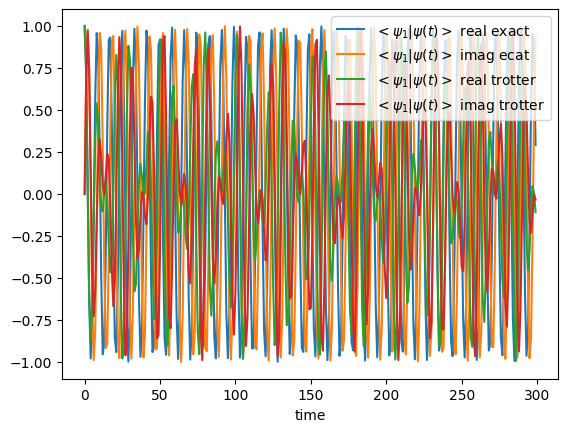

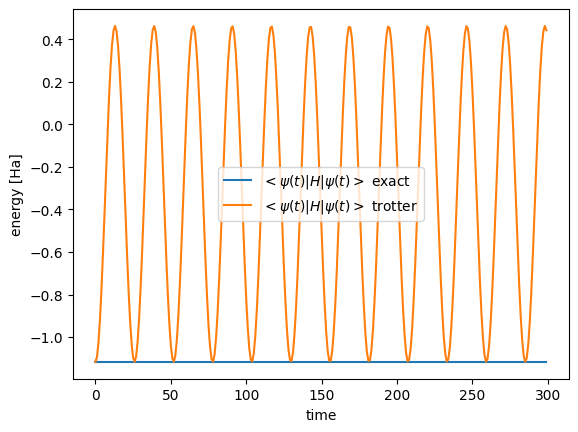

In [16]:
from openfermion import get_sparse_operator
import matplotlib.pyplot as plt


sparse_h = get_sparse_operator(ha_qubit, n_qubits=1)

overlap = []
overlap_t = []
energy = []
energy_t = []

times = []

dt = 0.5
import numpy as np
for t in np.linspace(0, 200, 300):
    sparse_state_t = time_evolution(t)
    overlap.append((sparse_state.T.conj() @ sparse_state_t)[0, 0])
    energy.append((sparse_state_t.T.conj() @ sparse_h @ sparse_state_t)[0, 0].real)

    sparse_state_t = time_evolution_trotter(t, 1)
    overlap_t.append((sparse_state.T.conj() @ sparse_state_t)[0, 0])
    energy_t.append((sparse_state_t.T.conj() @ sparse_h @ sparse_state_t)[0, 0].real)

    times.append(t)

print(energy[0].real)
plt.plot(np.real(overlap), label='$<\psi_1 | \psi(t)>$ real exact')
plt.plot(np.imag(overlap), label='$<\psi_1 | \psi(t)>$ imag ecat')
plt.plot(np.real(overlap_t), label='$<\psi_1 | \psi(t)>$ real trotter')
plt.plot(np.imag(overlap_t), label='$<\psi_1 | \psi(t)>$ imag trotter')

plt.legend()
plt.xlabel('time')
#plt.ylim(-1, 1)

plt.figure()
plt.plot(np.real(energy), label='$<\psi(t) | H | \psi(t)>$ exact')
plt.plot(np.real(energy_t), label='$<\psi(t) | H | \psi(t)>$ trotter')

plt.legend()
plt.ylabel('energy [Ha]')
plt.xlabel('time')


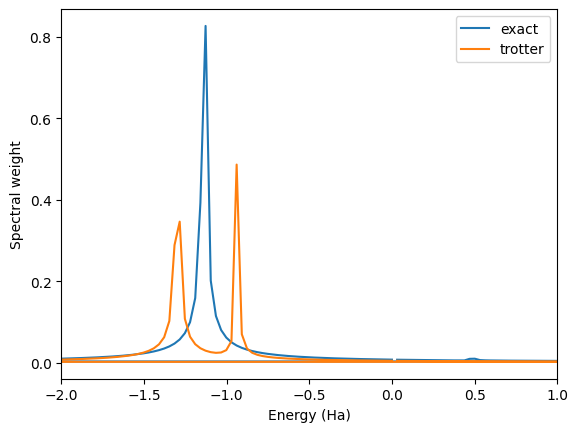

In [17]:

dt = times[1] - times[0]
freq = np.fft.fftfreq(len(times), dt)
energy = -2*np.pi*freq   # sign given by the convention e^{-iEt}

fft_signal = np.fft.fft(overlap)/len(overlap)
plt.plot(energy, np.abs(fft_signal), label='exact')

fft_signal_t = np.fft.fft(overlap_t)/len(overlap_t)
plt.plot(energy, np.abs(fft_signal_t), label='trotter')

plt.xlabel("Energy (Ha)")
plt.ylabel("Spectral weight")
plt.xlim(-2,1)
plt.legend()

In [18]:
from scipy.signal import find_peaks

peaks, properties = find_peaks(
    np.abs(fft_signal),
    prominence=0.1
)

for peak in peaks:
    print(
        f"E = {energy[peak]: .6f}, "
        f"Spectral weight = {np.abs(fft_signal[peak]): .6f}"
    )

E = -1.127203, Spectral weight =  0.827386


Circuit

In [19]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# define generator for time evolution
te_qubit = 1j * ha_qubit

def get_trotter_step(theta):

    # Build the ansatz
    qc = QuantumCircuit(1)

    for op, coef in te_qubit.terms.items():

        for qubit, pauli in op:
            if pauli == 'X':
                qc.h(qubit)
            elif pauli == 'Y':
                qc.rx(np.pi / 2, [qubit])

        for qubit, pauli in op[1:]:
            qc.cx(qubit, op[0][0])

        if len(op) > 0:
            qc.rz(2 * theta * coef.imag, op[0][0])

        for qubit, pauli in reversed(op[1:]):
            qc.cx(qubit, op[0][0])

        for qubit, pauli in op:
            if pauli == 'X':
                qc.h(qubit)
            elif pauli == 'Y':
                qc.rx(np.pi / 2, [qubit])

    return qc

def get_time_evolution_circuit(theta, n_steps=1):

    qc = QuantumCircuit(1)

    delta_t = theta / n_steps
    for _ in range(n_steps):
        qc.compose(get_trotter_step(delta_t), inplace=True)

    return qc

print('deph:', get_time_evolution_circuit(10).depth())

deph: 4


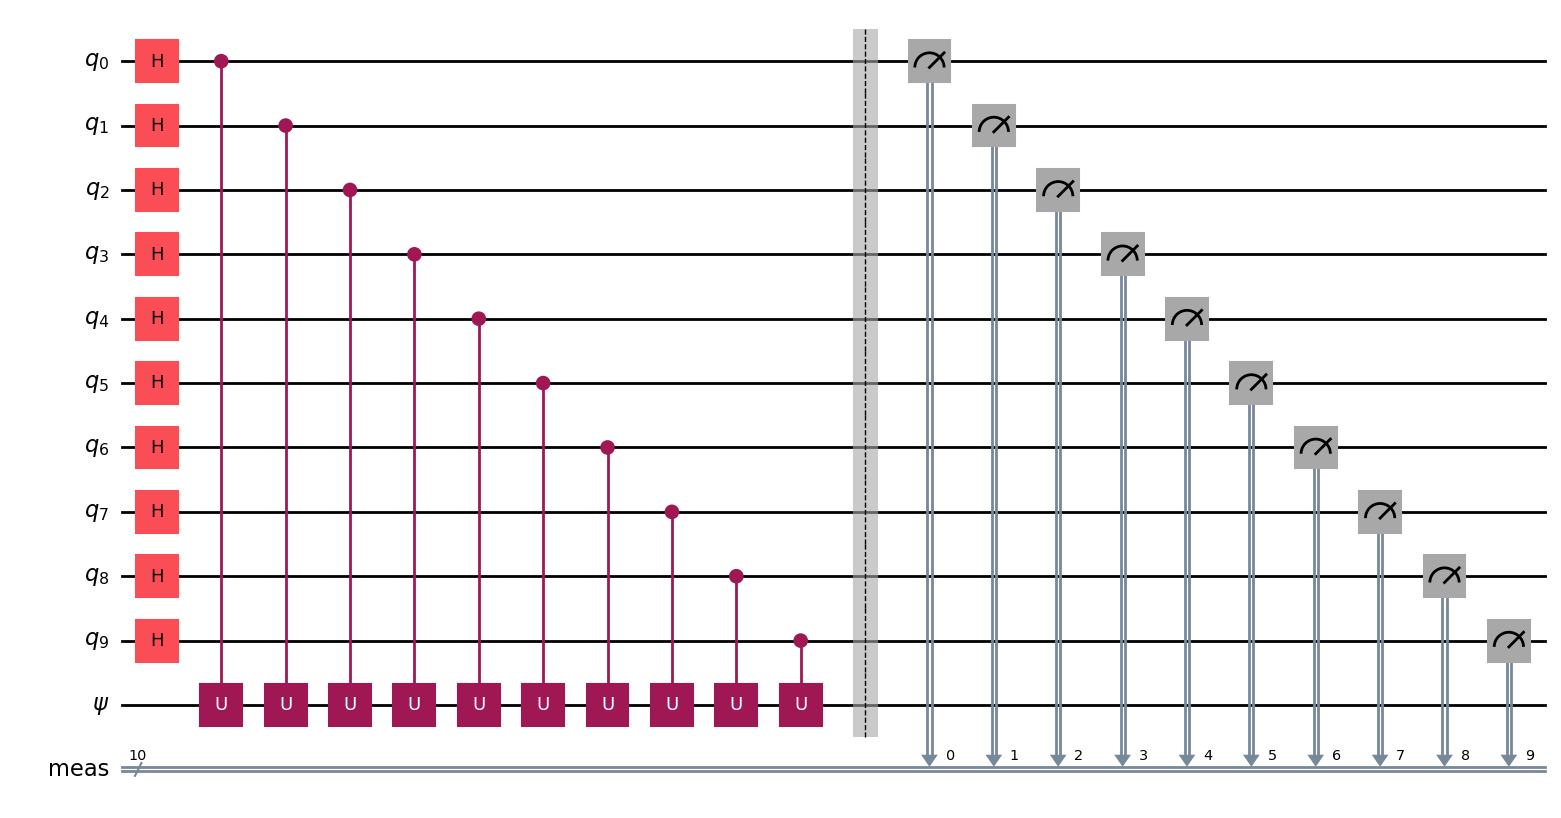

In [26]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

n_qubits = 10
q = QuantumRegister(n_qubits, 'q')
c_reg = ClassicalRegister(n_qubits, 'meas')

anc = QuantumRegister(1, r'\psi')

# build signal circuit
qc_signal = QuantumCircuit(q, anc, c_reg)

dt = 0.5

for i in range(n_qubits):
    qc_signal.h(q[i])

for i in range(n_qubits):

    circ_te = get_time_evolution_circuit(2**i*dt)
    U_gate = circ_te.to_gate(label="U")
    U_controlled_gate = U_gate.control(1)
    qc_signal.append(U_controlled_gate, [q[i], anc[0]])


    #U_controlled_gate = (circ_te.to_gate(label="U")).control(i)

qc_signal.barrier()
for i in range(n_qubits):
    qc_signal.measure(q[i], c_reg[i])

qc_signal.draw('mpl')

{'0000000000': 115, '0000000001': 88, '0000000010': 108, '0000000011': 95, '0000000100': 91, '0000000101': 100, '0000000110': 103, '0000000111': 104, '0000001000': 104, '0000001001': 94, '0000001010': 96, '0000001011': 103, '0000001100': 97, '0000001101': 91, '0000001110': 98, '0000001111': 95, '0000010000': 94, '0000010001': 98, '0000010010': 100, '0000010011': 87, '0000010100': 90, '0000010101': 99, '0000010110': 96, '0000010111': 90, '0000011000': 108, '0000011001': 101, '0000011010': 79, '0000011011': 92, '0000011100': 116, '0000011101': 104, '0000011110': 96, '0000011111': 95, '0000100000': 90, '0000100001': 101, '0000100010': 106, '0000100011': 97, '0000100100': 101, '0000100101': 119, '0000100110': 80, '0000100111': 80, '0000101000': 91, '0000101001': 78, '0000101010': 86, '0000101011': 98, '0000101100': 95, '0000101101': 117, '0000101110': 88, '0000101111': 92, '0000110000': 96, '0000110001': 95, '0000110010': 91, '0000110011': 95, '0000110100': 78, '0000110101': 81, '000011011

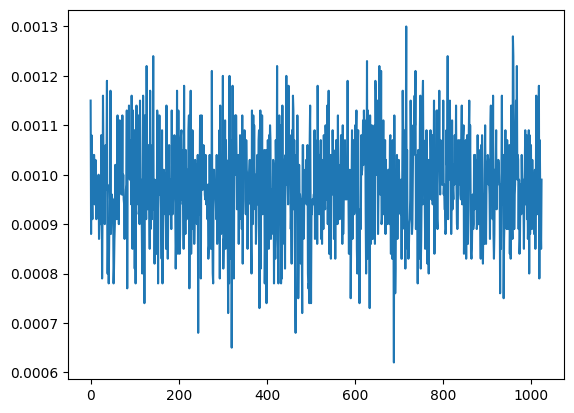

In [27]:
from qiskit.primitives import StatevectorSampler

n_shots = 100000
sampler = StatevectorSampler()
result = sampler.run([qc_signal], shots=n_shots).result()
counts = result[0].data.meas.get_counts()

counts_ordered = dict(sorted(counts.items(), key=lambda item: int(item[0], 2)))
print(counts_ordered)

signal = np.zeros(2**n_qubits)
for k, v in counts_ordered.items():
    bit_num = int(k, 2)
    print(k, bit_num, v/n_shots)
    signal[bit_num] = v/n_shots

import matplotlib.pyplot as plt

plt.plot(range(2**n_qubits), signal)

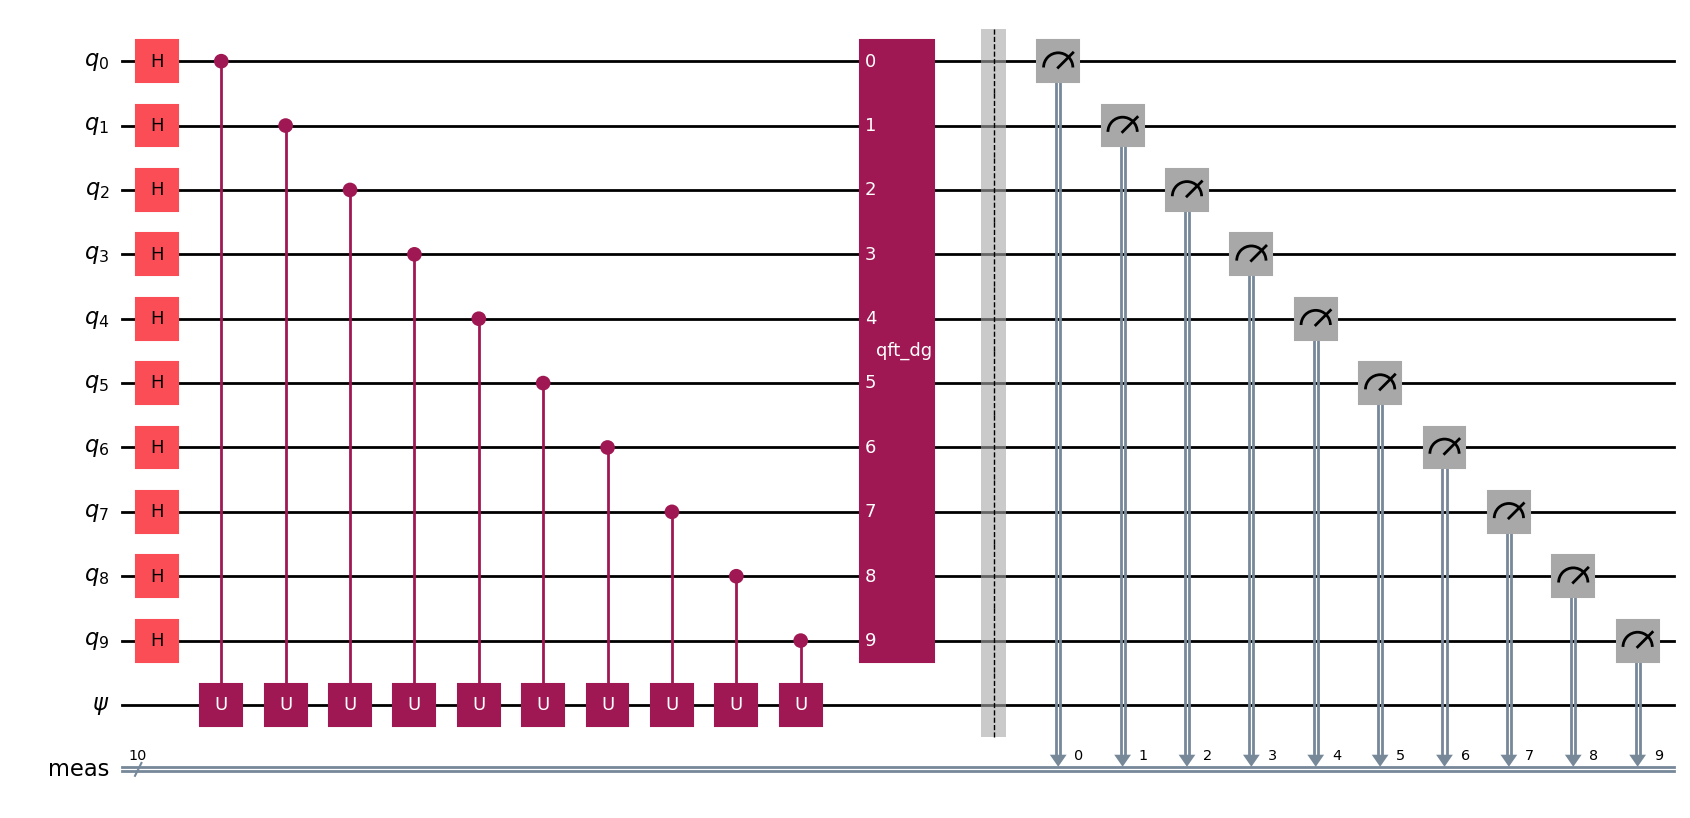

In [28]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import QFTGate


identity_coef = ha_qubit.terms.get((), 0.0)

n_qubits = 10
q = QuantumRegister(n_qubits, 'q')
c_reg = ClassicalRegister(n_qubits, "meas")

anc = QuantumRegister(1, r'\psi')

# build Hadamard test circuit
qc_qpe = QuantumCircuit(q, anc, c_reg)

dt = 0.5

# intial state
#qc_qpe.x(anc[0])

for i in range(n_qubits):
    qc_qpe.h(q[i])

for i in range(n_qubits):

    circ_te = get_time_evolution_circuit(2**i*dt, n_steps=100)
    U_gate = circ_te.to_gate(label="U")
    U_controlled_gate = U_gate.control(1)
    qc_qpe.append(U_controlled_gate, [q[i], anc[0]])

    # Add the identity contribution to the control phase
    # qc_qpe.p(-identity_coef * 2**i*dt, q[i])

# Apply QFT
qc_qpe.append(QFTGate(n_qubits).inverse(), q)


qc_qpe.barrier()
for i in range(n_qubits):
    qc_qpe.measure(q[i], c_reg[i])

qc_qpe.draw('mpl')

{'0000000000': 18, '0000000001': 171, '0000000011': 20, '0000000100': 13, '0000000101': 150, '0000000110': 3, '0000000111': 22, '0000001000': 15, '0000001001': 191, '0000001010': 1, '0000001011': 26, '0000001100': 22, '0000001101': 164, '0000001110': 2, '0000001111': 35, '0000010000': 21, '0000010001': 245, '0000010011': 36, '0000010100': 19, '0000010101': 206, '0000010110': 1, '0000010111': 50, '0000011000': 35, '0000011001': 386, '0000011011': 55, '0000011100': 31, '0000011101': 343, '0000011110': 3, '0000011111': 66, '0000100000': 58, '0000100001': 635, '0000100011': 75, '0000100100': 48, '0000100101': 556, '0000100110': 1, '0000100111': 114, '0000101000': 76, '0000101001': 991, '0000101011': 123, '0000101100': 95, '0000101101': 1077, '0000101110': 9, '0000101111': 254, '0000110000': 155, '0000110001': 2124, '0000110011': 302, '0000110100': 228, '0000110101': 2740, '0000110110': 20, '0000110111': 739, '0000111000': 525, '0000111001': 7426, '0000111010': 1, '0000111011': 1500, '00001

Text(0, 0.5, 'Spectral weight')

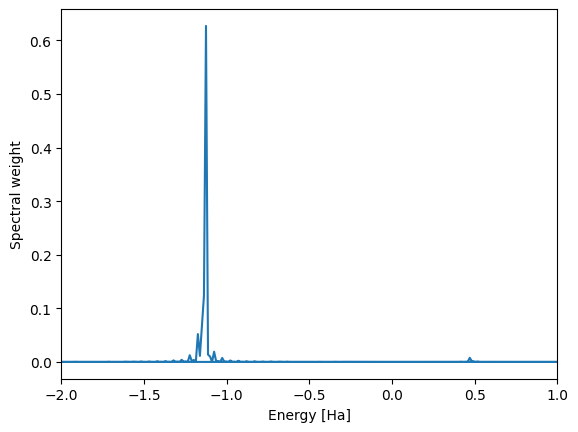

In [29]:
from qiskit.primitives import StatevectorSampler

n_shots = 1000000
sampler = StatevectorSampler()
result = sampler.run([qc_qpe], shots=n_shots).result()
counts = result[0].data.meas.get_counts()

counts_ordered = dict(sorted(counts.items(), key=lambda item: int(item[0], 2)))
print(counts_ordered)

fft_signal = np.zeros(2**n_qubits)
for k, v in counts_ordered.items():
    bit_num = int(k, 2)
    print(k, bit_num, v/n_shots)
    fft_signal[bit_num] = v/n_shots

import matplotlib.pyplot as plt

k = np.arange(2**n_qubits)
omega = 2 * np.pi * np.fft.fftfreq(2**n_qubits, d=dt)

#freq = np.array(range(2**n_qubits)) /dt*0.1 # 0.1?
#energy = -2*np.pi*freq   # sign given by the convention e^{-iEt}

identity_coef = ha_qubit.terms.get((), 0.0)
energy = -omega + identity_coef
plt.plot(energy, np.abs(fft_signal))
plt.xlim(-2, 1)
#plt.ylim(0, 0.01 )
plt.xlabel('Energy [Ha]')
plt.ylabel("Spectral weight")


In [30]:
from scipy.signal import find_peaks

peaks, properties = find_peaks(
    np.abs(fft_signal),
    prominence=0.1
)

for peak in peaks:
    print(
        f"E = {energy[peak]: .6f}, "
        f"Spectral weight = {np.abs(fft_signal[peak]): .6f}"
    )

E = -1.124741, Spectral weight =  0.627198


- increase & decrease the number trotter steps to check the effect